# IND320 Project Work, Part 4

**Student:** Sara Christine Gjerløw  

- **GitHub repository:** https://github.com/SaraGjerlow/ind320-SaraGjerlow  
- **Streamlit app:** https://ind320-saragjerlow.streamlit.app
- **Screencast:** https://youtu.be/-u9hxGgUopI

## 1. Imports and database connection

In [1]:
from io import StringIO
from pathlib import Path
import json
import time
import tomllib

import geopandas as gpd
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import requests
from IPython.display import Image
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from river import time_series

In [2]:
# The connection string is read from the file that stays out of GitHub.
with open(Path("../.streamlit/secrets.toml"), "rb") as f:
    secrets = tomllib.load(f)

mongo_client = MongoClient(secrets["mongo"]["uri"], server_api=ServerApi("1"))
database = mongo_client["ind320"]

try:
    mongo_client.admin.command("ping")
    print("Connected to MongoDB.")
except Exception as error:
    print(error)

Connected to MongoDB.


## 2. App structure

I drew this before changing any code. The star marks the pages that use the
area chosen on Home, and the names in brackets are where the data comes from.

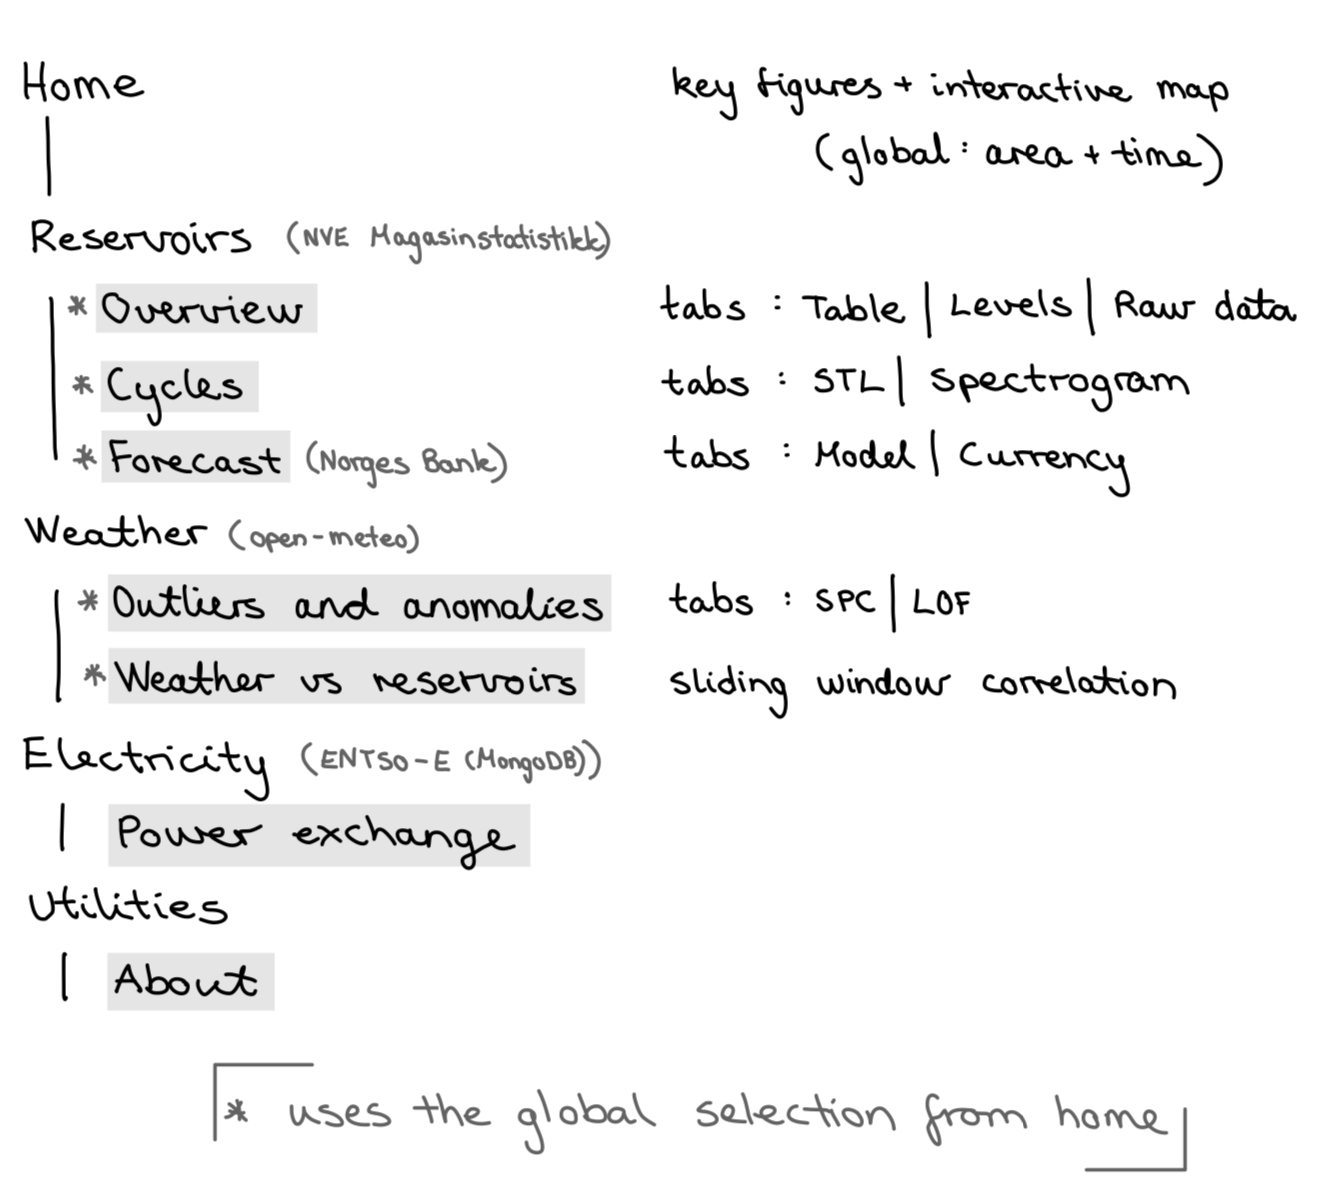

In [3]:
Image("../images/app_structure.jpeg", width=950)

## 3. Currency rates from Norges Bank

Norges Bank has an open API that needs no key. The key in the URL is frequency,
base currency, quote currency and tenor, so B.EUR+USD.NOK.SP gives daily EUR
and USD rates against the krone.

The answer is CSV with semicolons, one row per date and currency. The function
turns that into one row per date and one column per currency.

In [4]:
NB_URL = "https://data.norges-bank.no/api/data/EXR"


def download_currency(start_date, end_date, currencies=("EUR", "USD")):
    """Download daily exchange rates against NOK from Norges Bank."""
    # Frequency, base currency, quote currency, tenor.
    key = f"B.{'+'.join(currencies)}.NOK.SP"

    response = requests.get(
        f"{NB_URL}/{key}",
        params={
            "startPeriod": start_date,
            "endPeriod": end_date,
            "format": "csv",
            "locale": "en",
        },
        timeout=60,
    )
    response.raise_for_status()

    # Norges Bank separates the columns with semicolons, not commas.
    data = pd.read_csv(StringIO(response.text), sep=";")
    data["TIME_PERIOD"] = pd.to_datetime(data["TIME_PERIOD"])

    # One column per currency is easier to join with the other data later.
    rates = data.pivot(index="TIME_PERIOD", columns="BASE_CUR",
                       values="OBS_VALUE")
    rates.index.name = "date"
    rates.columns.name = None

    return rates


# The euro did not exist before 1999, so the history starts there.
TODAY = str(pd.Timestamp.today().date())
rates = download_currency("1999-01-01", TODAY)

print("Rows:", len(rates))
print("From", rates.index.min().date(), "to", rates.index.max().date())
rates.tail(3)

Rows: 7026
From 1999-01-04 to 2026-11-23


,EUR,USD
date,,
2026-11-19,10.6475,9.6866
2026-11-20,10.7180,9.7525
2026-11-23,10.7285,9.8076


In [5]:
figure = px.line(
    rates,
    title="EUR and USD against NOK",
    labels={"value": "NOK per unit", "date": "Date", "variable": "Currency"},
)
figure.show()

Only business days, so weekends and holidays are missing. EUR starts in 1999
because the euro did not exist before that. The two rates follow each other
closely, since both are measured against the same krone.

## 4. Time zones across the data sources

The forecast joins all four sources, so their timestamps have to mean the same
thing. I check what each one actually returns instead of assuming.

In [6]:
def describe_time(name, times):
    """One row describing the timestamps of one source."""
    return {
        "source": name,
        "dtype": str(times.dtype),
        "time zone": str(times.dt.tz),
        "first": times.min(),
        "last": times.max(),
        "values": len(times),
    }


# Magasinstatistikk, weekly dates straight from the NVE API.
nve = pd.DataFrame(requests.get(
    "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData",
    timeout=60,
).json())
nve["dato_Id"] = pd.to_datetime(nve["dato_Id"])

# Cross-border flows, written to MongoDB in part 2.
flows = pd.DataFrame(list(
    database["crossborder_flows"].find({}, {"_id": 0, "timestamp": 1})
))
flows["timestamp"] = pd.to_datetime(flows["timestamp"])

# Weather, written to MongoDB in part 3.
weather = pd.DataFrame(list(database["area_weather"].find(
    {"area_type": "EL", "area_number": 3}, {"_id": 0, "time": 1}
)))
weather["time"] = pd.to_datetime(weather["time"])

pd.DataFrame([
    describe_time("NVE Magasinstatistikk", nve["dato_Id"]),
    describe_time("ENTSO-E via MongoDB", flows["timestamp"]),
    describe_time("open-meteo via MongoDB", weather["time"]),
    describe_time("Norges Bank", rates.index.to_series()),
]).set_index("source")

,dtype,time zone,first,last,values
source,,,,,
NVE Magasinstatistikk,datetime64[us],None,1995-01-08 00:00:00,2026-11-15 00:00:00,14967
ENTSO-E via MongoDB,datetime64[us],None,2024-10-15 20:00:00,2026-10-15 19:00:00,140144
open-meteo via MongoDB,datetime64[us],None,2024-01-01 00:00:00,2024-12-31 23:00:00,8784
Norges Bank,datetime64[us],None,1999-01-04 00:00:00,2026-11-23 00:00:00,7026


In [7]:
# Are the date-only sources really only dates?
print("NVE weekdays: ", nve["dato_Id"].dt.day_name().unique().tolist())
print("NVE times:    ", nve["dato_Id"].dt.time.unique().tolist())
print("Norges Bank:  ", rates.index.time.min(), "to", rates.index.time.max())

# Do the hourly sources cover a whole day?
print("ENTSO-E:      ", flows["timestamp"].dt.hour.nunique(), "distinct hours")
print("open-meteo:   ", weather["time"].dt.hour.nunique(), "distinct hours")

NVE weekdays:  ['Sunday']
NVE times:     [datetime.time(0, 0)]
Norges Bank:   00:00:00 to 00:00:00
ENTSO-E:       24 distinct hours
open-meteo:    24 distinct hours


None of the four has a time zone, but they split into two kinds.

NVE and Norges Bank are dates only. Both sit at midnight, so the 00:00 is
padding and not a measurement time. NVE always uses Sundays.

ENTSO-E and open-meteo are hourly with all 24 hours, and both are in UTC.
ENTSO-E publishes in UTC, and open-meteo returns UTC unless you ask for
something else, which I never did. So there is nothing to convert.

The risk is in the code, not the data. The hourly series are naive, so reading
them as Oslo time would shift them an hour or two with no error at all. I
treat everything as UTC and say so in the app.

What really differs is resolution. Weekly, hourly and business-daily cannot be
joined directly, so the forecast resamples everything to weeks.

## 5. Forecasting reservoir filling

The filling is weekly, so the forecast works in weeks. Twelve weeks ahead is
about three months.

The model needs weather over the same period as the filling, and that goes
back to 1995. The 2024 data from part 3 is far too short for a season of 52
weeks.

Open-meteo charges by locations times days, so a long history is cheap if you
use few locations. Ten points over thirty years costs about the same as a
thousand over two weeks. I ask for daily values, since everything ends up as
weeks anyway.

In [8]:
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

# Daily aggregates, since the forecast works in weeks.
DAILY_VARIABLES = ["temperature_2m_mean", "precipitation_sum", "snowfall_sum"]

# Ten points with three variables fits about seven years under the limit.
YEARS_PER_REQUEST = 7


def download_daily_weather(area_type, area_number, start_date, end_date,
                           n_points=10):
    """Download a long daily weather history for one area, in chunks of years."""
    documents = database["area_points"].find(
        {"area_type": area_type, "area_number": area_number},
        {"_id": 0, "latitude": 1, "longitude": 1},
    )
    points = pd.DataFrame(list(documents)).head(n_points)

    # Split the period into chunks that stay under the minutely limit.
    chunks = []
    period_start = pd.Timestamp(start_date)
    final_end = pd.Timestamp(end_date)

    while period_start <= final_end:
        period_end = period_start + pd.DateOffset(years=YEARS_PER_REQUEST)
        period_end = min(period_end - pd.Timedelta(days=1), final_end)
        chunks.append((period_start, period_end))
        period_start = period_end + pd.Timedelta(days=1)

    pieces = []
    for number, (chunk_start, chunk_end) in enumerate(chunks):
        print(f"  {chunk_start.date()} to {chunk_end.date()}")

        response = requests.get(
            ARCHIVE_URL,
            params={
                "latitude": ",".join(points["latitude"].astype(str)),
                "longitude": ",".join(points["longitude"].astype(str)),
                "start_date": str(chunk_start.date()),
                "end_date": str(chunk_end.date()),
                "daily": ",".join(DAILY_VARIABLES),
                "models": "era5",
            },
            timeout=300,
        )
        response.raise_for_status()

        results = response.json()

        # One location gives a single object back, several give a list.
        if isinstance(results, dict):
            results = [results]

        # Add the locations together and divide at the end, as in part 3.
        total = None
        for result in results:
            daily = pd.DataFrame(result["daily"])
            daily["time"] = pd.to_datetime(daily["time"])
            daily = daily.set_index("time")

            if total is None:
                total = daily
            else:
                total = total + daily

        pieces.append(total / len(results))

        # Wait out the minutely limit, but not after the last chunk.
        if number < len(chunks) - 1:
            time.sleep(65)

    return pd.concat(pieces).reset_index()


def load_daily_weather(area_type, area_number, start_date, end_date):
    """Read the history from MongoDB, and only download it if it is missing.

    The app reads the same collection, so the download happens once and never
    again, instead of every time the notebook is run.
    """
    collection = database["area_weather_daily"]
    stored = list(collection.find(
        {"area_type": area_type, "area_number": area_number}, {"_id": 0}
    ))

    if stored:
        weather = pd.DataFrame(stored)
        weather["time"] = pd.to_datetime(weather["time"])
        weather = weather.drop(columns=["area_type", "area_number"])
        print("Read from MongoDB.")
        return weather.sort_values("time").reset_index(drop=True)

    print(f"Downloading {area_type} {area_number}, {start_date} to {end_date}")
    weather = download_daily_weather(area_type, area_number, start_date, end_date)

    # The area is written into every row, so the app can filter on it.
    documents = []
    for row in weather.to_dict("records"):
        row["area_type"] = area_type
        row["area_number"] = area_number
        documents.append(row)

    collection.insert_many(documents)
    print("Downloaded and stored.")

    return weather

In [9]:
# ERA5 lags a few days behind, so the period stops a week before today.
HISTORY_START = "1995-01-01"
HISTORY_END = str((pd.Timestamp.today() - pd.Timedelta(days=7)).date())

daily_weather = load_daily_weather("EL", 3, HISTORY_START, HISTORY_END)

print("Days:", len(daily_weather))
daily_weather.describe().round(2)

Read from MongoDB.
Days: 11634


,time,temperature_2m_mean,precipitation_sum,snowfall_sum
count,11634,11634.00,11634.00,11634.00
mean,2010-12-04 12:00:00,4.85,4.66,0.70
min,1995-01-01 00:00:00,-19.70,0.00,0.00
25%,2002-12-18 06:00:00,0.34,0.37,0.00
50%,2010-12-04 12:00:00,4.63,2.60,0.08
75%,2018-11-20 18:00:00,10.14,7.00,0.80
max,2026-11-07 00:00:00,21.63,51.03,11.10
std,NaN,6.44,5.69,1.29


11634 days with no gaps. The average daily precipitation is 4.66 mm, and the
2024 series from part 3 averaged 0.207 mm per hour, which is 4.97 mm per day.
Two separate downloads landing on nearly the same number is a good sign.

In [10]:
# The other EL areas, so the weather pages work for all of them and not only
# EL 3. Areas already stored are skipped, so this cell can be run again later.
for number in [1, 2, 4, 5]:
    print(f"EL {number}")

    # Checked first, so the wait below only happens on a real download.
    stored = database["area_weather_daily"].count_documents(
        {"area_type": "EL", "area_number": number}, limit=1
    )

    try:
        weather = load_daily_weather("EL", number, HISTORY_START, HISTORY_END)
        print(f"  {len(weather)} days")
    except requests.HTTPError as error:
        print(f"  Stopped: {error}")
        print("  The limit is used up. Run this cell again in an hour.")
        break

    # Wait out the minutely limit before starting the next download.
    if stored == 0:
        time.sleep(65)

EL 1
Read from MongoDB.
  11637 days
EL 2
Read from MongoDB.
  11637 days
EL 4
Read from MongoDB.
  11637 days
EL 5
Read from MongoDB.
  11637 days


All five EL areas now have the same daily history, so the weather pages work
for the whole area type and not only for EL 3. EL 3 ends up with 11634 days
and the others with 11637, because EL 3 was downloaded a few days earlier and
ERA5 keeps moving its end date forward. VASS and NO are still without weather,
and NO has no sampled points at all, so it cannot be downloaded.

The three sources have three resolutions, so I put them on one weekly index.
NVE dates each week to the Sunday it ends on, so resampling the other two to
weeks ending on Sunday puts them on exactly the same dates.

Temperature is averaged over the week, while precipitation and snowfall are
summed. The currency rates are carried forward across weekends first.

In [11]:
# How each weather column is turned from days into weeks.
WEEKLY_WEATHER = {
    "temperature_2m_mean": "mean",
    "precipitation_sum": "sum",
    "snowfall_sum": "sum",
}


def build_weekly_frame(reservoirs, daily_weather, rates, area="EL 3"):
    """Put the reservoir, weather and currency data on one weekly index."""
    area_rows = reservoirs[reservoirs["area"] == area].sort_values("dato_Id")

    # The fill level is a fraction in the API, so it is turned into percent.
    fill = area_rows.set_index("dato_Id")["fyllingsgrad"] * 100
    fill = fill[~fill.index.duplicated(keep="first")]

    # W-SUN labels each week by the Sunday it ends on, just like NVE does.
    weather = daily_weather.set_index("time").resample("W-SUN").agg(WEEKLY_WEATHER)

    # Weekends are missing from the rates, so they are carried forward first.
    currency = rates.resample("D").ffill().resample("W-SUN").mean()

    # Built column by column on the reservoir index, so the dates always match.
    frame = pd.DataFrame(index=fill.index)
    frame["fill_level"] = fill

    for column in weather.columns:
        frame[column] = weather[column]

    for column in currency.columns:
        frame[column] = currency[column]

    # Rain adds water, so it affects the change in filling rather than the level.
    frame["fill_change"] = frame["fill_level"].diff()

    # Snow takes about twenty weeks to turn into meltwater, see section 6.
    frame["snow_lagged"] = frame["snowfall_sum"].shift(20)

    return frame


# The area column is the same one the app uses, for example "EL 3".
nve["area"] = nve["omrType"] + " " + nve["omrnr"].astype(str)

weekly = build_weekly_frame(nve, daily_weather, rates, area="EL 3")

print("Weeks:", len(weekly))
weekly.tail(3).round(2)

Weeks: 1663


,fill_level,temperature_2m_mean,precipitation_sum,snowfall_sum,EUR,USD,fill_change,snow_lagged
dato_Id,,,,,,,,
2026-11-01,72.01,7.51,44.98,1.19,10.35,9.28,0.25,0.32
2026-11-08,71.87,4.84,10.89,0.28,10.44,9.33,-0.14,0.07
2026-11-15,69.73,NaN,NaN,NaN,10.58,9.52,-2.14,0.01


In [12]:
# Which columns each data source contributes as exogenous variables.
SOURCES = {
    "weather": ["temperature_2m_mean", "precipitation_sum", "snowfall_sum"],
    "currency": ["EUR", "USD"],
    "lagged snow": ["snow_lagged"],
}


def forecast_filling(weekly, horizon=12, history_weeks=520, sources=(),
                     p=2, d=1, q=1, m=52, sp=1, sd=1, sq=0):
    """Forecast the reservoir filling some weeks ahead with River's SNARIMAX.

    horizon is weeks to predict, history_weeks is weeks of training data, and
    sources picks the exogenous variables. p, d and q are the AR, differencing
    and MA orders, m the season length, and sp, sd and sq the seasonal ones.
    The last horizon weeks are held back, so the numbers are out of sample.
    """
    exogenous = []
    for source in sources:
        exogenous = exogenous + SOURCES[source]

    # Rows without every needed column are dropped, then the tail is kept.
    used = weekly[["fill_level"] + exogenous].dropna()
    used = used.tail(history_weeks + horizon)

    train = used.iloc[:-horizon]
    test = used.iloc[-horizon:]

    started = time.time()

    model = time_series.SNARIMAX(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq)

    # River learns one observation at a time, which is what makes it online.
    for stamp, row in train.iterrows():
        x = {c: float(row[c]) for c in exogenous} if exogenous else None
        model.learn_one(y=float(row["fill_level"]), x=x)

    seconds = time.time() - started

    # The forecast needs the exogenous values for the weeks ahead as well.
    xs = None
    if exogenous:
        xs = [{c: float(r[c]) for c in exogenous} for _, r in test.iterrows()]

    predicted = model.forecast(horizon=horizon, xs=xs)

    # A fill level cannot be below zero or above a hundred percent.
    predicted = np.clip(np.array(predicted, dtype=float), 0, 100)
    actual = test["fill_level"].to_numpy()

    result = pd.DataFrame(
        {"actual": actual.round(1), "predicted": predicted.round(1)},
        index=test.index,
    )
    result["error"] = (result["predicted"] - result["actual"]).round(1)

    summary = {
        "training weeks": len(train),
        "exogenous variables": len(exogenous),
        "seconds to fit": round(seconds, 2),
        "MAE": round(float(np.mean(np.abs(predicted - actual))), 2),
    }

    # Two years of history behind the forecast, so the season is visible.
    recent = used["fill_level"].iloc[-104:]

    figure = go.Figure()
    figure.add_trace(go.Scatter(x=recent.index, y=recent.to_numpy(),
                                name="Observed", line=dict(width=1.5)))
    figure.add_trace(go.Scatter(x=result.index, y=result["predicted"],
                                name="Forecast",
                                line=dict(width=2.5, dash="dash")))
    figure.update_layout(
        title=f"Fill level forecast for the next {horizon} weeks",
        xaxis_title="Date",
        yaxis_title="Fill level (%)",
        hovermode="x unified",
        height=430,
    )

    return figure, result, summary

In [13]:
# The default settings: ten years of history, no exogenous variables.
figure, result, summary = forecast_filling(weekly)
figure.show()

print(summary)
result

{'training weeks': 520, 'exogenous variables': 0, 'seconds to fit': 0.06, 'MAE': 4.88}


,actual,predicted,error
dato_Id,,,
2026-08-30,62.7,63.5,0.8
2026-09-06,63.3,62.9,-0.4
2026-09-13,65.2,63.9,-1.3
2026-09-20,68.1,63.4,-4.7
2026-09-27,71.5,63.9,-7.6
2026-10-04,71.9,63.2,-8.7
2026-10-11,72.5,65.2,-7.3
2026-10-18,72.5,65.6,-6.9
2026-10-25,71.8,66.2,-5.6


The forecast gets the autumn rise right, but is too careful about how far it
goes. The errors start positive and end negative, so it sits above the real
curve at first and below it at the end. Fitting takes less than a tenth of a
second, so the app can retrain every time a setting changes.

In [14]:
# Each setting changes one thing, so it is clear what caused the difference.
settings = [
    ("Default", {}),
    ("With weather", dict(sources=("weather",))),
    ("With weather and currency", dict(sources=("weather", "currency"))),
    ("Short history, 4 years", dict(history_weeks=208)),
    ("Long history, 30 years", dict(history_weeks=1600)),
    ("No seasonal part", dict(m=1, sp=0, sd=0)),
    ("Simpler model, p=1 q=0", dict(p=1, q=0)),
    ("Horizon 26 weeks", dict(horizon=26)),
    ("No seasonal, with weather", dict(m=1, sp=0, sd=0, sources=("weather",))),
    ("No seasonal, horizon 26", dict(m=1, sp=0, sd=0, horizon=26)),
    ("Lagged snow only", dict(sources=("lagged snow",))),
    ("Weather and lagged snow", dict(sources=("weather", "lagged snow"))),
]

rows = []
for label, options in settings:
    figure, result, summary = forecast_filling(weekly, **options)
    summary["setting"] = label
    rows.append(summary)

comparison = pd.DataFrame(rows).set_index("setting")
comparison

,training weeks,exogenous variables,seconds to fit,MAE
setting,,,,
Default,520,0,0.04,4.88
With weather,520,3,0.06,2.46
With weather and currency,520,5,0.05,2.77
"Short history, 4 years",208,0,0.01,5.37
"Long history, 30 years",1600,0,0.10,5.02
No seasonal part,520,0,0.03,4.15
"Simpler model, p=1 q=0",520,0,0.03,5.11
Horizon 26 weeks,520,0,0.04,11.84
"No seasonal, with weather",520,3,0.12,3.08


### Findings

Weather helps most of all. The plain model gives 4.88, and adding temperature,
precipitation and snow brings it to 2.46. Rain and meltwater are what fill a
reservoir, so that makes sense.

Snow with a twenty week lag is not much on its own, 4.11, but on top of the
other weather it gives 1.95, the best result in the table. That lag comes from
section 6, where snowfall correlates best with the filling twenty weeks later.
It was nice to see a finding from one part actually improve another.

Currency does not help. Adding the rates pushes the error back up to 2.77. They
have no physical link to a reservoir, so they only add noise.

History length barely matters, and more is not better. Four years gives 5.37,
ten years 4.88 and thirty years 5.02, while thirty years takes two and a half
times as long to fit.

Dropping the seasonal part helps a little over twelve weeks, 4.15 against 4.88,
but it falls apart over a longer horizon. Over twenty-six weeks the model
without a season gives 41.90 against 11.84 with it, because without a season it
just continues the recent slope.

The two improvements do not combine. No season plus weather gives 3.08, which
is worse than weather alone at 2.46.

### Default in the app

The seasonal model with weather and lagged snow: p=2, d=1, q=1, m=52, sp=1,
sd=1, sq=0, ten years of history and twelve weeks ahead. It gives 1.95, the
best of everything I tried, and it keeps working when the user changes the
horizon.

All the settings are measured on the same twelve weeks, so the winner might
only suit that period. Several end dates would be the proper test.

## 6. Sliding window correlation

This shows whether two series move together, and whether that changes over
time.

The lag shifts the weather backwards, so a lag of four compares this week's
filling with the weather four weeks ago. The window is how many weeks go into
each correlation.

The reservoir side can be the fill level or the weekly change in it. That
turns out to matter more than either setting.

In [15]:
# The names used in the app menus, pointing at the columns in the table.
WEATHER_COLUMNS = {
    "Temperature": "temperature_2m_mean",
    "Precipitation": "precipitation_sum",
    "Snowfall": "snowfall_sum",
}

RESERVOIR_COLUMNS = {
    "Fill level": "fill_level",
    "Weekly change in fill level": "fill_change",
}


def sliding_correlation(weekly, weather_column="precipitation_sum",
                        reservoir_column="fill_change", lag=0, window=52):
    """Rolling correlation between weather and the reservoir data.

    lag shifts the weather backwards in weeks, and window is how many weeks go
    into each correlation.
    """
    pair = pd.DataFrame({
        "weather": weekly[weather_column].shift(lag),
        "reservoir": weekly[reservoir_column],
    }).dropna()

    correlation = pair["weather"].rolling(window).corr(pair["reservoir"])
    correlation = correlation.dropna()

    figure = go.Figure()
    figure.add_trace(go.Scatter(x=correlation.index, y=correlation.to_numpy(),
                                name="Correlation", line=dict(width=1.5)))

    # A line at zero, so it is easy to see where the sign flips.
    figure.add_hline(y=0, line_width=1, line_dash="dot")

    figure.update_layout(
        title=f"{weather_column} against {reservoir_column}, "
              f"lag {lag} weeks, window {window} weeks",
        xaxis_title="Date",
        yaxis_title="Correlation",
        yaxis_range=[-1, 1],
        hovermode="x unified",
        height=400,
    )

    summary = {
        "windows": len(correlation),
        "mean": round(float(correlation.mean()), 3),
        "min": round(float(correlation.min()), 3),
        "max": round(float(correlation.max()), 3),
    }

    return figure, correlation, summary


def correlation_by_lag(weekly, weather_column="precipitation_sum",
                       reservoir_column="fill_change", max_lag=26, window=52):
    """Run the correlation once per lag, to see which delay fits best."""
    rows = []
    for lag in range(0, max_lag + 1):
        figure, correlation, summary = sliding_correlation(
            weekly, weather_column, reservoir_column, lag=lag, window=window
        )
        rows.append({"lag": lag, "mean correlation": summary["mean"]})

    table = pd.DataFrame(rows).set_index("lag")

    figure = go.Figure()
    figure.add_trace(go.Bar(x=table.index, y=table["mean correlation"]))
    figure.add_hline(y=0, line_width=1, line_dash="dot")
    figure.update_layout(
        title=f"Average correlation by lag, {weather_column} "
              f"against {reservoir_column}",
        xaxis_title="Lag (weeks)",
        yaxis_title="Mean correlation",
        height=380,
    )

    return figure, table

In [16]:
# The same weather variable against the level and against the change.
for column in ["fill_level", "fill_change"]:
    figure, correlation, summary = sliding_correlation(
        weekly, "precipitation_sum", column, lag=0, window=52
    )
    print(f"{column:12s}", summary)

# Which delay fits best, for each of the three weather variables.
for name, column in WEATHER_COLUMNS.items():
    figure, table = correlation_by_lag(weekly, column, "fill_change")
    best = table["mean correlation"].abs().idxmax()
    print(f"{name:14s} strongest at lag {best:2d} weeks, "
          f"correlation {table.loc[best, 'mean correlation']:+.3f}")

figure.show()

fill_level   {'windows': 1611, 'mean': 0.178, 'min': -0.27, 'max': 0.523}
fill_change  {'windows': 1610, 'mean': 0.092, 'min': -0.279, 'max': 0.48}
Temperature    strongest at lag  0 weeks, correlation +0.669
Precipitation  strongest at lag  6 weeks, correlation -0.221
Snowfall       strongest at lag 20 weeks, correlation +0.467


### Findings

Temperature is strongest at no lag, +0.669. Warm weeks are weeks when the
filling rises, but that is not cause and effect. Both follow the same yearly
cycle.

Snowfall is the interesting one. At no lag it is negative, around -0.4: when it
snows the water does not run into the reservoir, and it is winter, so the
magazines are being drained. The correlation then climbs, crosses zero around
ten weeks and reaches +0.467 at twenty. Twenty weeks is the time from snow
falling in January to the melt filling the reservoirs in late spring.

Precipitation is the weakest, -0.221 at six weeks. Rain is far less seasonal,
so there is less yearly cycle to ride on.

Level or change matters, but not the way I expected. For precipitation at no
lag the level is stronger, 0.178 against 0.092. The change only wins once a lag
is applied.

Snowfall at about twenty weeks is the most promising extra input for the
model, because it is the one correlation that comes from physics and not from
a shared season. Section 5 confirms it: adding snow at that lag brings the
forecast error from 2.46 down to 1.95.

## 7. Shapefiles to GeoJSON

The app needs the area borders for its map, but it should not read shapefiles,
because that would mean geopandas on Streamlit Cloud. GeoJSON is plain text
the app opens with json.load, so I convert here instead.

One file per area type: EL is the price areas, VASS is the five NVE regions
merged into three, and NO is all of them dissolved into one country outline.

GeoJSON uses longitude and latitude, so the coordinates come out of UTM. I also
simplify to 500 metres and round to four decimals, which makes the files
twenty-seven times smaller while the map looks the same.

In [17]:
SHAPEFILE_DIR = Path("../shapefiles")
GEOJSON_DIR = Path("../geojson")

# NVE's five regions grouped into the three areas Magasinstatistikk reports.
REGION_TO_VASS = {"RS": 1, "RØ": 1, "RV": 2, "RM": 3, "RN": 3}

# Simplified while the coordinates are still in metres, which is easier to judge.
SIMPLIFY_METRES = 500

# Four decimals of a degree, roughly eleven metres.
COORDINATE_PRECISION = 1e-4


def build_area_layers():
    """Read the shapefiles and return one table per area type."""
    el = gpd.read_file(
        SHAPEFILE_DIR / "Budområder/Budområder.shp", encoding="utf-8"
    )
    el["area_number"] = el["budomr"].str.replace("NO ", "").astype(int)
    el = el[["area_number", "geometry"]].sort_values("area_number")

    vass = gpd.read_file(
        SHAPEFILE_DIR / "NVE_Region/NVE_Region.shp", encoding="utf-8"
    )
    vass["area_number"] = vass["REGION"].map(REGION_TO_VASS)
    vass = vass.dissolve(by="area_number", as_index=False)
    vass = vass[["area_number", "geometry"]]

    # The whole country is every price area merged into one outline.
    country = el.dissolve()[["geometry"]].copy()
    country["area_number"] = 0

    return {"EL": el, "VASS": vass, "NO": country}


def save_geojson(layers):
    """Simplify, convert to longitude and latitude, and write one file each."""
    GEOJSON_DIR.mkdir(exist_ok=True)

    for area_type, frame in layers.items():
        simple = frame.copy()
        simple["geometry"] = simple.geometry.simplify(SIMPLIFY_METRES)

        # GeoJSON always uses longitude and latitude.
        simple = simple.to_crs(epsg=4326)
        simple["geometry"] = simple.geometry.set_precision(COORDINATE_PRECISION)

        # The app reads these to know which area was clicked.
        simple["area_type"] = area_type
        simple["area"] = area_type + " " + simple["area_number"].astype(str)

        columns = ["area_type", "area_number", "area", "geometry"]
        path = GEOJSON_DIR / f"{area_type}.geojson"
        path.write_text(simple[columns].to_json(), encoding="utf-8")

        print(f"{area_type:5s} {len(simple)} areas, "
              f"{path.stat().st_size / 1024:6.1f} kB")


layers = build_area_layers()
save_geojson(layers)

EL    5 areas,   24.1 kB
VASS  3 areas,   27.5 kB
NO    1 areas,    7.9 kB


In [18]:
with open(GEOJSON_DIR / "EL.geojson", encoding="utf-8") as file:
    el_geojson = json.load(file)

print("Features:", len(el_geojson["features"]))
print("Properties:", el_geojson["features"][0]["properties"])

# A fake value per area, only to check that the colouring works.
preview = pd.DataFrame({
    "area": [f"EL {number}" for number in range(1, 6)],
    "value": [1, 2, 3, 4, 5],
})

figure = px.choropleth_map(
    preview,
    geojson=el_geojson,
    locations="area",
    featureidkey="properties.area",
    color="value",
    map_style="carto-positron",
    center={"lat": 65, "lon": 15},
    zoom=3.2,
    opacity=0.45,
    height=600,
)
figure.update_layout(margin=dict(l=0, r=0, t=0, b=0))
figure.show()

Features: 5
Properties: {'area_type': 'EL', 'area_number': 1, 'area': 'EL 1'}


59 kB in total, down from 1.6 MB. The preview shows that the file works
straight in Plotly: the five areas land in the right places and the colours
follow the value given per area.

## 8. Tests

The functions above are demonstrated with different settings as they are
written, but that only shows that they run. These tests give them inputs
where the answer is known in advance, so a wrong result fails instead of
looking plausible. They were added after the peer review pointed out that
there were no known-answer tests.

In [19]:
def check(name, condition):
    """Fail loudly if a test does not hold, and print it when it does."""
    assert condition, f"FAILED: {name}"
    print(f"ok  {name}")


# describe_time, on two timestamps where every answer is known.
sample_times = pd.Series(pd.to_datetime(["2024-01-01", "2024-01-03"]))
row = describe_time("sample", sample_times)

check("describe_time counts the values", row["values"] == 2)
check("describe_time finds the first", row["first"] == pd.Timestamp("2024-01-01"))
check("describe_time reports no time zone", row["time zone"] == "None")


# build_weekly_frame, on three small tables with constant weather.
test_dates = pd.date_range("2024-01-07", periods=30, freq="W-SUN")

test_nve = pd.DataFrame({
    "dato_Id": test_dates,
    "area": "EL 3",
    "fyllingsgrad": np.linspace(0.5, 0.8, len(test_dates)),
})

test_days = pd.DataFrame({
    "time": pd.date_range("2024-01-01", periods=7 * len(test_dates), freq="D"),
    "temperature_2m_mean": 1.0,
    "precipitation_sum": 2.0,
    "snowfall_sum": 3.0,
})

test_rates = pd.DataFrame(
    {"EUR": 11.0, "USD": 10.0},
    index=pd.date_range("2024-01-01", periods=7 * len(test_dates), freq="D"),
)

test_weekly = build_weekly_frame(test_nve, test_days, test_rates, area="EL 3")

# Two millimetres a day has to come out as fourteen a week, and one degree
# every day has to stay one degree, or the aggregation is wrong.
check("fill level is turned into percent",
      round(test_weekly["fill_level"].iloc[0], 1) == 50.0)
check("every week ends on a Sunday",
      set(test_weekly.index.dayofweek) == {6})
check("temperature is averaged over the week",
      round(test_weekly["temperature_2m_mean"].iloc[1], 2) == 1.0)
check("precipitation is summed over the week",
      round(test_weekly["precipitation_sum"].iloc[1], 2) == 14.0)
check("snow is lagged by twenty weeks",
      test_weekly["snow_lagged"].iloc[:20].isna().all())


# sliding_correlation, on a series compared against itself and its mirror.
test_index = pd.date_range("2020-01-05", periods=200, freq="W-SUN")
wave = np.sin(np.arange(200) / 5)

same = pd.DataFrame({"precipitation_sum": wave, "fill_change": wave},
                    index=test_index)
figure, correlation, summary = sliding_correlation(same, window=52)
check("a series against itself correlates +1", abs(summary["mean"] - 1.0) < 0.001)

opposite = same.copy()
opposite["fill_change"] = -wave
figure, correlation, summary = sliding_correlation(opposite, window=52)
check("a mirrored series correlates -1", abs(summary["mean"] + 1.0) < 0.001)


# correlation_by_lag, on a series with a delay of eight weeks built into it.
signal = np.sin(np.arange(300) / 7)
lagged = pd.DataFrame(
    {"precipitation_sum": signal, "fill_change": np.roll(signal, 8)},
    index=pd.date_range("2018-01-07", periods=300, freq="W-SUN"),
)

figure, table = correlation_by_lag(lagged, max_lag=20, window=52)
check("the built in lag of eight weeks is the strongest",
      int(table["mean correlation"].abs().idxmax()) == 8)


# forecast_filling, on a clean yearly cycle with a little noise on top.
test_weeks = pd.date_range("2010-01-03", periods=700, freq="W-SUN")
position = np.arange(len(test_weeks))
noise = np.random.default_rng(0).normal(0, 1, len(test_weeks))

synthetic = pd.DataFrame(
    {"fill_level": 55 + 25 * np.sin(2 * np.pi * position / 52) + noise},
    index=test_weeks,
)

figure, result, summary = forecast_filling(synthetic, horizon=6,
                                           history_weeks=200)

check("one row per forecast week", len(result) == 6)
check("the forecast ends on the last week of the data",
      result.index[-1] == synthetic.index[-1])
check("every prediction is a possible fill level",
      result["predicted"].between(0, 100).all())
check("the error column is the difference",
      bool(np.allclose(result["error"],
                       (result["predicted"] - result["actual"]).round(1))))

print("\nAll tests passed.")

ok  describe_time counts the values
ok  describe_time finds the first
ok  describe_time reports no time zone
ok  fill level is turned into percent
ok  every week ends on a Sunday
ok  temperature is averaged over the week
ok  precipitation is summed over the week
ok  snow is lagged by twenty weeks
ok  a series against itself correlates +1
ok  a mirrored series correlates -1
ok  the built in lag of eight weeks is the strongest
ok  one row per forecast week
ok  the forecast ends on the last week of the data
ok  every prediction is a possible fill level
ok  the error column is the difference

All tests passed.


## 9. Log

I started with the notebook as always. The currency function from Norges Bank
was easy once I found out that their CSV uses semicolons instead of commas.
The time zone section was more useful than I expected. I had never checked
what time zone my four sources actually use, and writing them into one table
made it clear why everything has to be converted before it is joined.

Then I went over to the forecasting. River trains one week at a time instead
of all at once, which fits a weekly series that keeps growing. My first model
only used the fill level itself and got an MAE of 4.88 percentage points.
Adding the weather brought it down to 2.46. What really helped was something
the correlation section found: snowfall correlates best with the weekly change
in filling at a lag of about 20 weeks, not at zero. That is roughly how long it
takes for snow to melt and reach the reservoirs. With the lagged snow on top of
the weather, the error dropped to 1.95. Section 6 finds the lag, and section 5
uses it.

Then I rebuilt the app. I drew the page structure by hand first, and that
sketch is what the menu looks like now. Every matplotlib plot is replaced with
Plotly, so the plots can be hovered and zoomed. Giving the app its colours was
something I enjoyed, hihi. Each page has its own colour on headings, buttons,
sliders and plots, and the menu sections have one each, so you can see where
you are without reading.

The map on the front page is new. You can click an area and the choice follows
you to every other page. Colouring by weather works for the five EL areas,
which are the ones I downloaded daily weather for, so the correlation page and
the extra variables in the forecast work for all of EL. The three VASS areas
stay grey, and NO has no sampled points at all. open-meteo limits how much I
can download per day, so I stopped at EL.

For the bonus I did three tasks. Confidence intervals in SARIMAX, using
quantile loss in River, so the forecast has a band that gets wider further
ahead. Error handling, where every source raises the same kind of error and
the app shows a readable message instead of a traceback. And waiting time,
where everything that can be cached is cached and each wait has its own text.
One side effect is that most pages keep working for a while with no internet.

The peer review gave me three things. I added section 8 with known-answer
tests, since the functions were only demonstrated before. The SPC limit now
starts at four sigma instead of three, which is what my own text recommends.
And the anomaly detection uses day of year as a sine and a cosine instead of
the hour number, with the old setting still there to compare against.

## 10. AI declaration

Claude (Anthropic) was used for:
- Sparring on the structure of the app and which pages to split the work into
- Explanations of River and SNARIMAX, quantile loss, rolling correlation and
  Plotly animation
- Writing and reviewing code, including the conversion of every plot from
  matplotlib to Plotly
- Drafting text that I then went through and rewrote in my own words

All code was run, tested and adjusted by me. NVE, open-meteo, Norges Bank,
River and Streamlit documentation were used as primary sources.